In [ ]:
%load_ext autoreload
%autoreload 2

### Figure 5: Multi-dataset updating

 - __c)__ Average performance across tasks.
 - __d)__ MS retention.
 - __e)__ Acquisition delta mAP.
 - __f)__ Retention across future points.

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT.name not in ("CLSBN26", "PepCL_Manuscript"):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not find CLSBN26 project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "Data"
SRC_DIR = PROJECT_ROOT / "src"
FIGURES_DIR = PROJECT_ROOT / "Figures"
MODEL_CHECKPOINTS_DIR = PROJECT_ROOT / "Model_Checkpoints"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROJECT_ROOT in sys.path:", str(PROJECT_ROOT) in sys.path)

PROJECT_ROOT: /home/pchati/PepCL_Manuscript
PROJECT_ROOT in sys.path: True


In [ ]:
# get mhc pseudosequences (process before you use)
from Data.mhc_pseudo_seqs import mhc_seq_dict
mhc_seq_dict={k.removeprefix("HLA-").replace("*","").replace(":",""):v for k,v in mhc_seq_dict.items()}

# imports
from src.general_utils import *
from src.get_feature_data import *
from src.plotting import *
from src.louvain_clustering import *
from src.resampled_jsd import *
from src.multi_dataset_updating_utils import *

# misc
import warnings
warnings.filterwarnings("ignore")
device="cuda"

In [ ]:
"""
Set figure output directory
"""
# create central repository and for this figure
central_figure_dir="Figure5"

# associated data dir
associated_data_dir=f"{central_figure_dir}/Associated_Data"

os.makedirs(central_figure_dir, exist_ok=True)
os.makedirs(associated_data_dir, exist_ok=True)

### Fig. 4c-d: Average performance across tasks and MS retention

In [ ]:
# load results
sequential_runs_outputs=load_dict_pickle(f"{DATA_DIR}/Multi_Dataset_Updating_Results/Sequential_Run_Results/sequential_runs_outputs.pkl")

seeded_allele_ap=sequential_runs_outputs["seeded_allele_ap"]
task_orders=sequential_runs_outputs["task_orders"]
method_names_suffixes_dict=sequential_runs_outputs["method_names_suffixes_dict"]

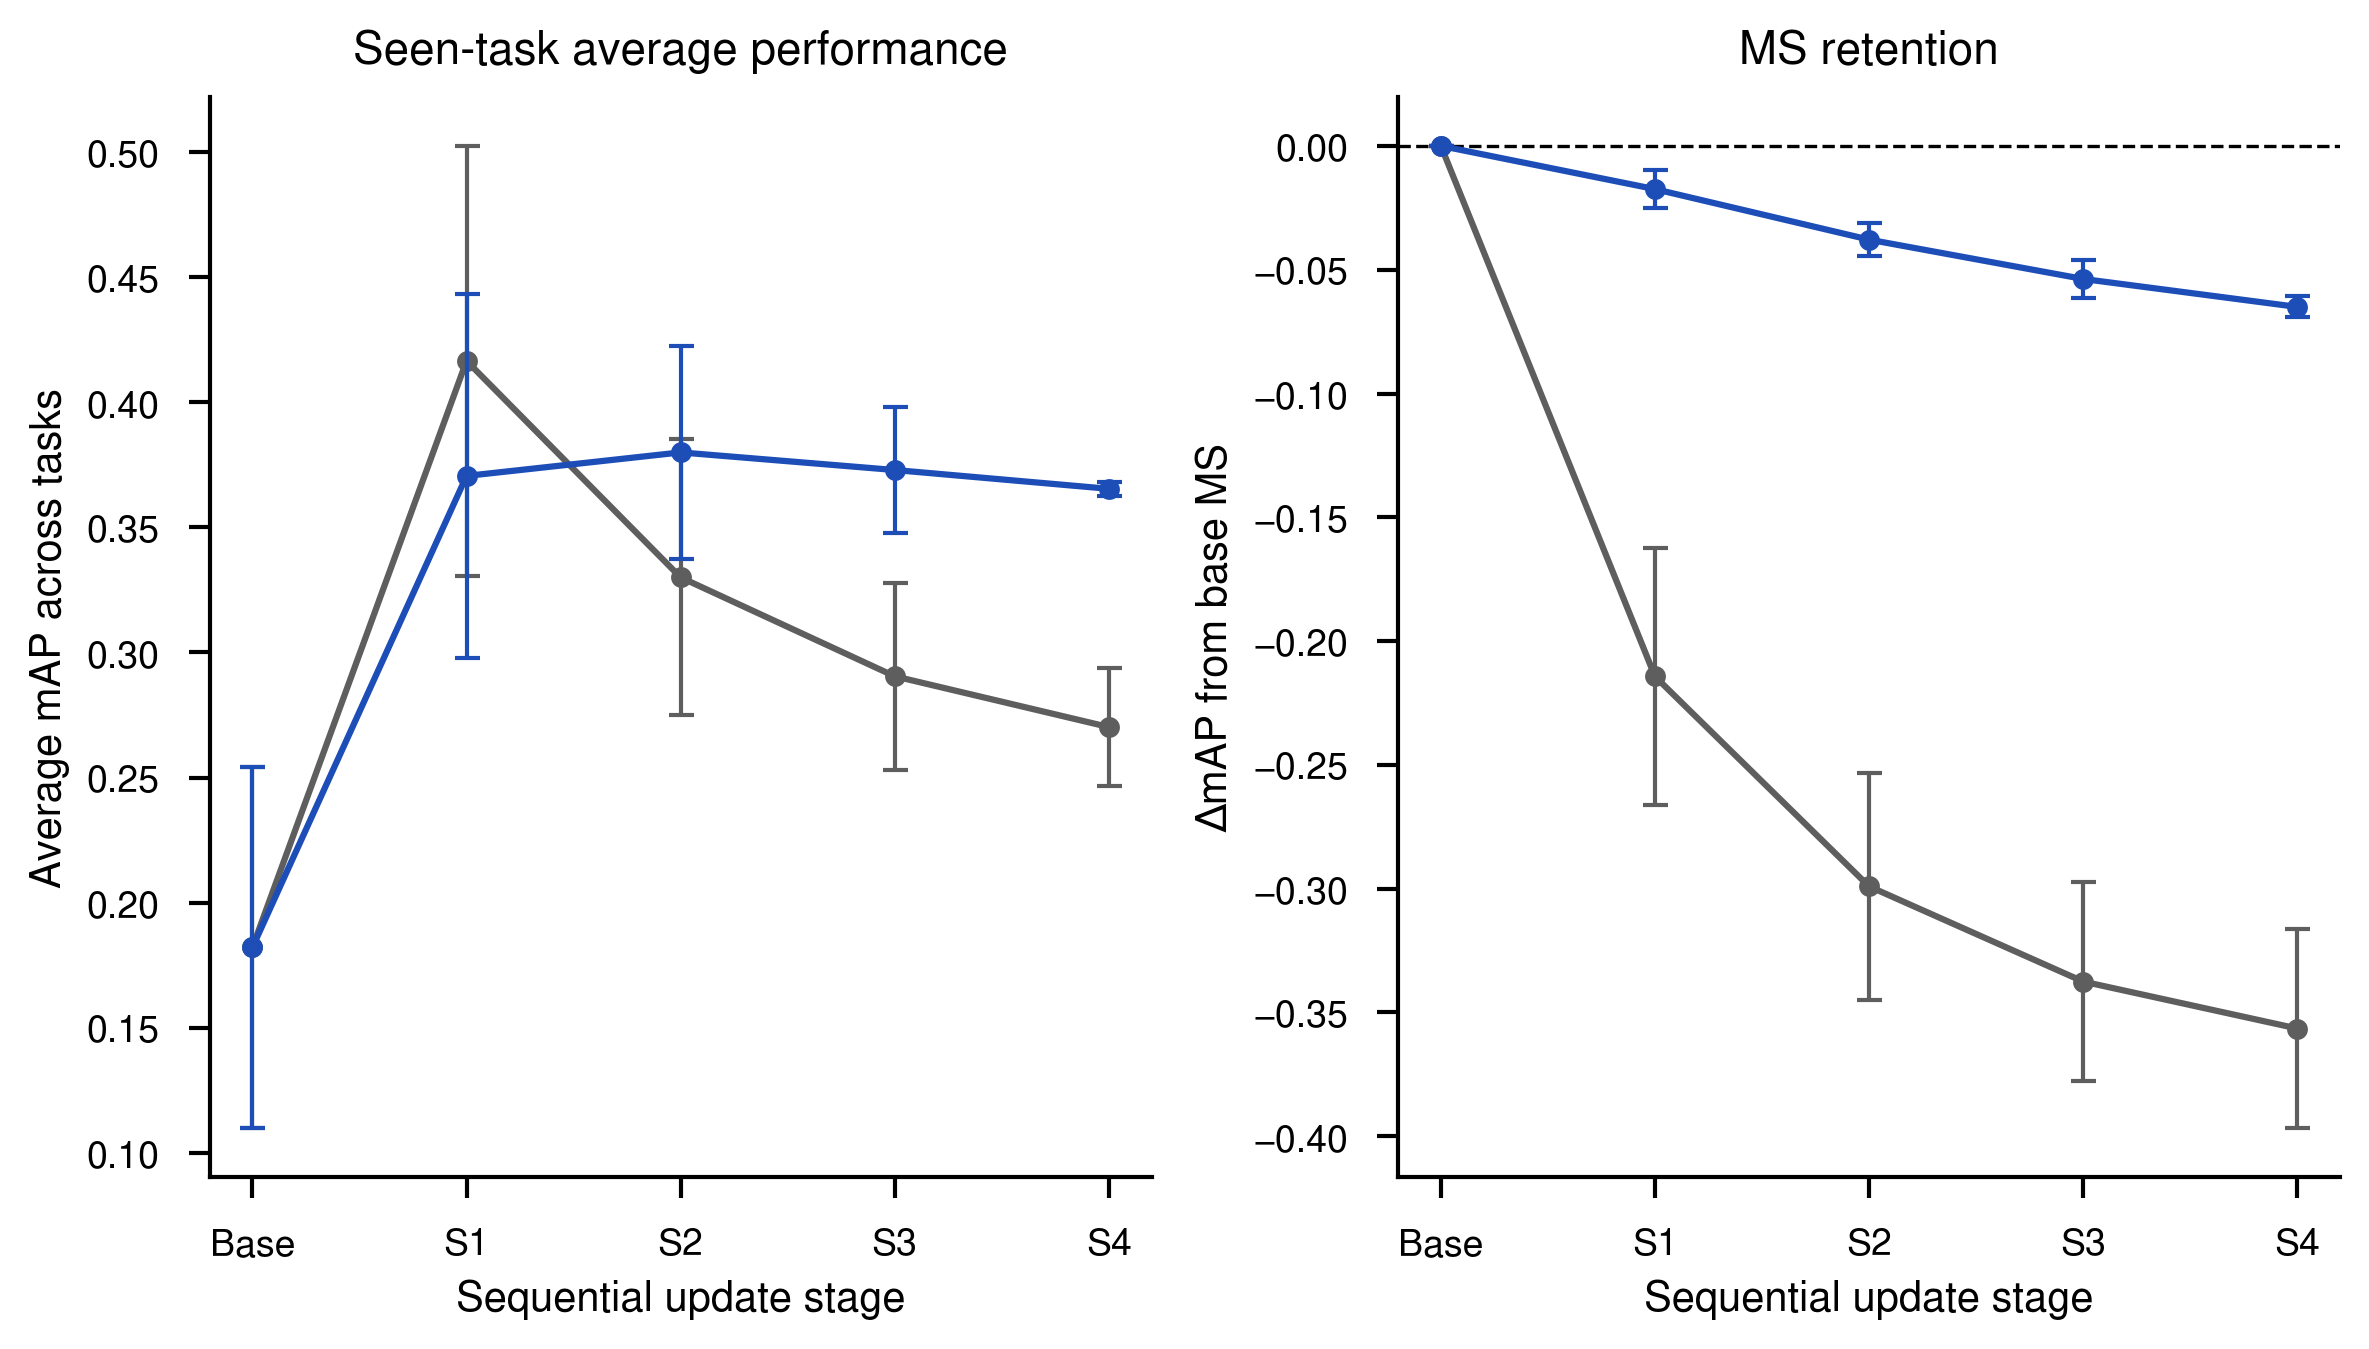

In [ ]:
# average performance and ms retention
method_names_suffixes_dict_temp={
    "FT":"_ft",
    "PepCL w/ Replay/DR (50% MS; Adaptive buffer)":
        "_pepcl_multi_replay_dr_full_buffer_50pct_ms",
}

cl_plot=plot_seeded_cl_seen_performance_and_ms_retention(
    seeded_allele_ap=seeded_allele_ap,
    task_orders=task_orders,
    method_suffixes=method_names_suffixes_dict_temp,
    base_score_col="mhcprime",

    interval="ci95",
    interval_unit="orders",

    method_labels={
        "FT":"FT",
        "PepCL w/ Replay/DR (50% MS; Adaptive buffer)":"PepCL",
    },
    method_colors={
        "FT":"#5e5e5e",
        "PepCL w/ Replay/DR (50% MS; Adaptive buffer)":"#1d4eb8",
    },

    figsize=(8, 4.6),
    dpi=300,
    default_font="Nimbus Sans",

    seen_title="Seen-task average performance",
    ms_title="MS retention",
    title_fontsize=11,
    title_bold=False,

    xlabel="Sequential update stage",
    seen_ylabel="Average mAP across tasks",
    ms_ylabel="ΔmAP from base MS",

    linewidth=1.5,
    marker="o",
    markersize=5,
    error_colors=None,
    error_linewidth=1.0,
    error_capsize=3.0,
    error_capthick=1.0,
    error_alpha=1.0,

    remove_top_spine=True,
    remove_right_spine=True,
    axis_linewidth=1.0,

    tick_length=5,
    tick_width=1.0,
    xtick_labelsize=9,
    ytick_labelsize=9,

    grid_alpha=0,

    show_legend=False,
    legend_panel=0,
    legend_loc="best",
    legend_frame=False,
    legend_fontsize=9,
    save_path=f"{central_figure_dir}/fig_5cd_seen_performance_ms_retention_line_plots"
)

In [ ]:
"""
Save data associated with figure
"""
# save_dict_pickle(cl_plot, f"{associated_data_dir}/cl_5cd_results.pkl")

### Fig. 4e: Acquisition across points

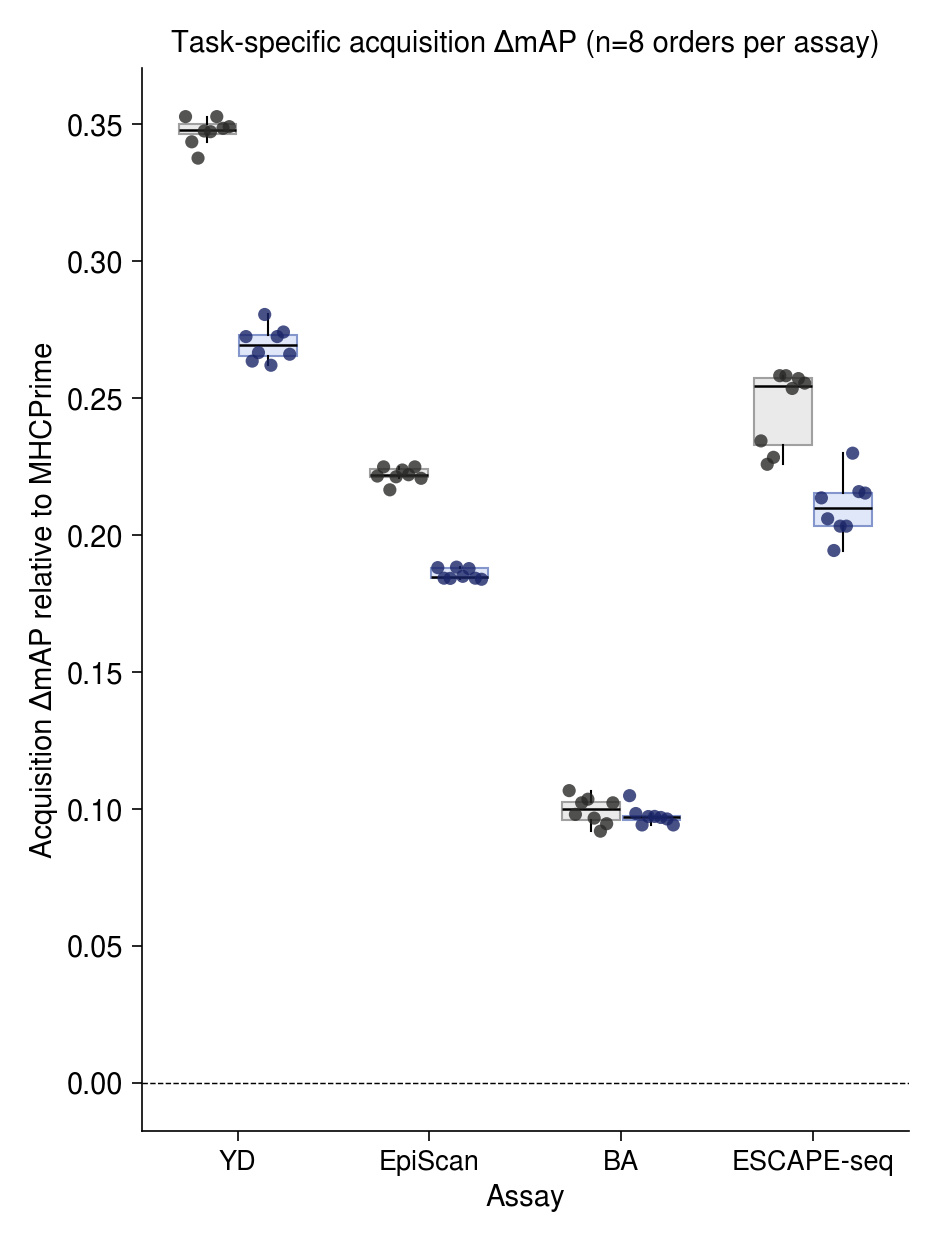

CPU times: user 694 ms, sys: 474 ms, total: 1.17 s
Wall time: 558 ms


In [ ]:
%%time
# plot mAP delta from mhcprime
method_names_suffixes_dict_temp={
    "FT":"_ft",
    "PepCL w/ Replay/DR (50% MS; Adaptive buffer)":
        "_pepcl_multi_replay_dr_full_buffer_50pct_ms",
}

method_colors_temp={
    "FT":"#bababa",
    "PepCL w/ Replay/DR (50% MS; Adaptive buffer)":"#9bb0ed",
}

box_edgecolors_temp={
    "FT":"#A1A0A0",
    "PepCL w/ Replay/DR (50% MS; Adaptive buffer)":"#8496cb",
}

acquisition_summary_df,fig,ax,acquisition_seed_df=plot_seeded_task_metric_boxplots(
    seeded_allele_ap=seeded_allele_ap,
    task_orders=task_orders,
    method_suffixes=method_names_suffixes_dict_temp,
    metric="acquisition_delta",
    base_score_col="mhcprime",
    method_colors=method_colors_temp,
    box_edgecolor_mode=box_edgecolors_temp,
    method_labels={
        "FT":"FT",
        "PepCL w/ Replay/DR (50% MS; Adaptive buffer)":"PepCL",
    },

    assay_labels={
        "yd":"YD",
        "episcan":"EpiScan",
        "ba":"BA",
        "escape":"ESCAPE-seq",
    },
    figsize=(3.3,4.6),
    dpi=300,
    title_fontsize=7,
    xlabel_fontsize=7,
    ylabel_fontsize=7,
    xtick_fontsize=6.5,
    ytick_fontsize=7,
    title_pad=4,
    xlabel_pad=2,
    ylabel_pad=2,
    axis_linewidth=0.40,
    tick_length=2.5,
    tick_width=0.40,
    tick_pad=2,
    box_width=0.30,
    group_width=0.40,
    box_facecolor_mode="method",
    box_alpha=0.3,
    box_linewidth=0.50,

    median_color="black",
    median_linewidth=0.60,

    whisker_color_mode="black",
    whisker_linewidth=0.50,
    whisker_linestyle="-",
    show_caps=False,
    point_colors={
        "FT":"#292928",
        "PepCL w/ Replay/DR (50% MS; Adaptive buffer)":"#1A2568",
    },
    point_edgecolors="none",
    point_edgewidths=0,
    point_alphas=0.8,
    point_sizes=10,
    point_markers="o",
    point_jitter_fraction=0.38,

    show_top_spine=False,
    show_right_spine=False,
    show_legend=False,
    grid=False,

    show_n=False,
    title="Task-specific acquisition ΔmAP (n=8 orders per assay)",
    xlabel="Assay",
    ylabel="Acquisition ΔmAP relative to MHCPrime",
    # save_path=f"{central_figure_dir}/fig_5e_task_acquisition_map_boxplot"
)

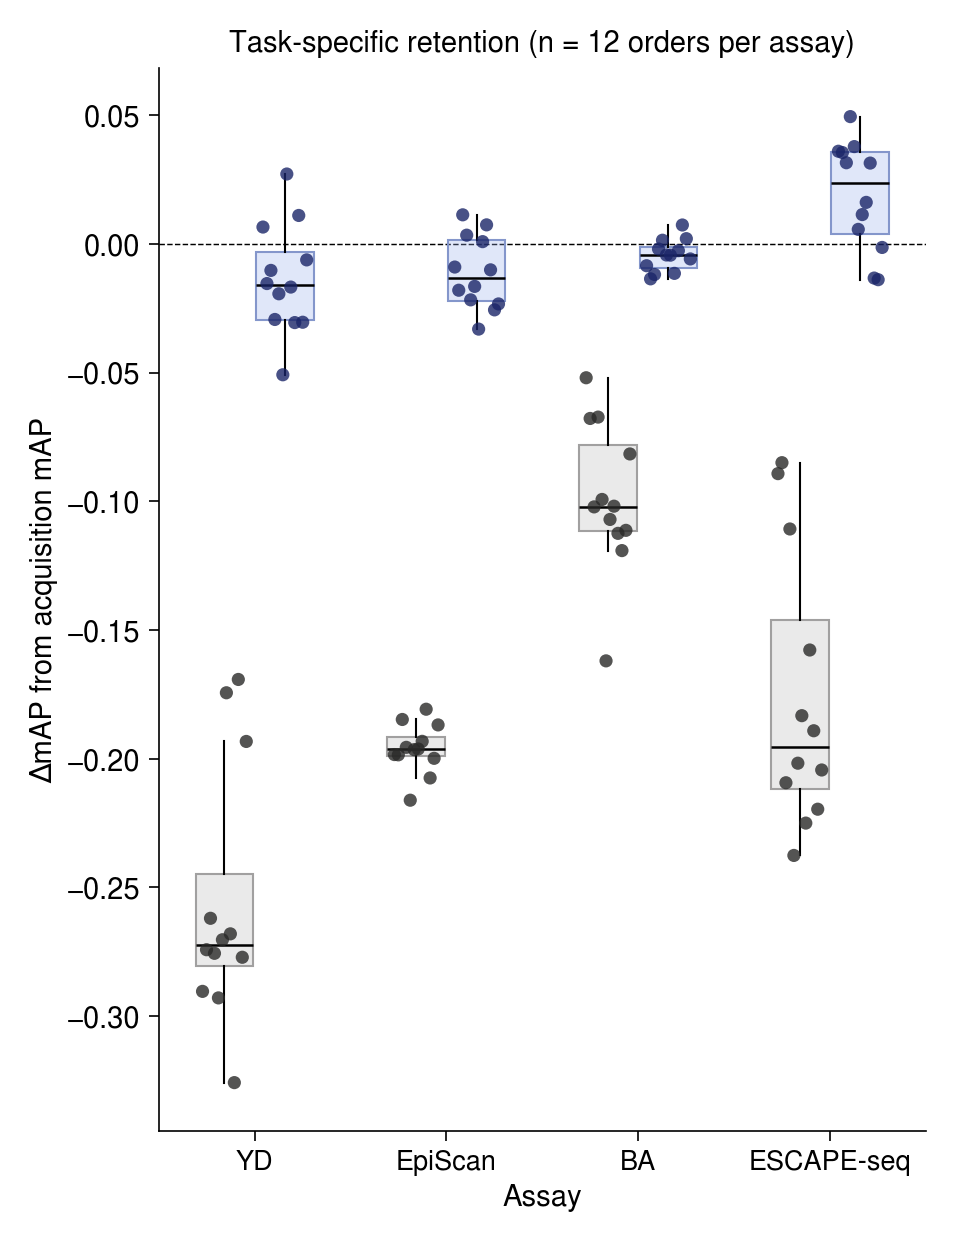

CPU times: user 341 ms, sys: 229 ms, total: 570 ms
Wall time: 292 ms


In [ ]:
%%time
# plot mAP delta from mhcprime
method_names_suffixes_dict_temp={
    "FT":"_ft",
    "PepCL w/ Replay/DR (50% MS; Adaptive buffer)":
        "_pepcl_multi_replay_dr_full_buffer_50pct_ms",
}

method_colors_temp={
    "FT":"#bababa",
    "PepCL w/ Replay/DR (50% MS; Adaptive buffer)":"#9bb0ed",
}

box_edgecolors_temp={
    "FT":"#A1A0A0",
    "PepCL w/ Replay/DR (50% MS; Adaptive buffer)":"#8496cb",
}

retention_summary_df,fig,ax,retention_seed_df=plot_seeded_task_metric_boxplots(
    seeded_allele_ap=seeded_allele_ap,
    task_orders=task_orders,
    method_suffixes=method_names_suffixes_dict_temp,
    metric="retention",
    retention_mode="all",

    method_colors=method_colors_temp,
    box_edgecolor_mode=box_edgecolors_temp,
    method_labels={
        "FT":"FT",
        "PepCL w/ Replay/DR (50% MS; Adaptive buffer)":"PepCL",
    },

    assay_labels={
        "yd":"YD",
        "episcan":"EpiScan",
        "ba":"BA",
        "escape":"ESCAPE-seq",
    },
    figsize=(3.3,4.6),
    dpi=300,
    title_fontsize=7,
    xlabel_fontsize=7,
    ylabel_fontsize=7,
    xtick_fontsize=6.5,
    ytick_fontsize=7,
    title_pad=4,
    xlabel_pad=2,
    ylabel_pad=2,
    axis_linewidth=0.40,
    tick_length=2.5,
    tick_width=0.40,
    tick_pad=2,
    box_width=0.30,
    group_width=0.40,
    box_facecolor_mode="method",
    box_alpha=0.3,
    box_linewidth=0.50,

    median_color="black",
    median_linewidth=0.60,

    whisker_color_mode="black",
    whisker_linewidth=0.50,
    whisker_linestyle="-",
    show_caps=False,
    point_colors={
        "FT":"#292928",
        "PepCL w/ Replay/DR (50% MS; Adaptive buffer)":"#1A2568",
    },
    point_edgecolors="none",
    point_edgewidths=0,
    point_alphas=0.8,
    point_sizes=10,
    point_markers="o",
    point_jitter_fraction=0.38,

    show_top_spine=False,
    show_right_spine=False,
    show_legend=False,
    grid=False,

    show_n=False,
    title="Task-specific retention (n = 12 orders per assay)",
    xlabel="Assay",
    ylabel="ΔmAP from acquisition mAP",

    # save_path=f"{central_figure_dir}/fig_5f_task_all_retention_map_boxplot"
)

In [ ]:
"""
Save associated data
"""
# retention_summary_df.to_csv(f"{associated_data_dir}/retention_summary_df.csv")
# retention_seed_df.to_csv(f"{associated_data_dir}/retention_seed_df.csv")
# acquisition_summary_df.to_csv(f"{associated_data_dir}/acquisition_summary_df.csv")
# acquisition_seed_df.to_csv(f"{associated_data_dir}/acquisition_seed_df.csv")